# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Beatrix Yustina Ena Fallo
- **Email:** beatrixfallo682@gmail.com
- **ID Dicoding:** beatrix_fallo

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1 (Pengaruh Kondisi Cuaca dan Status Hari terhadap Operasional):** Bagaimana perbandingan **rata-rata** peminjaman sepeda harian berdasarkan kondisi cuaca (Cerah, Berawan, Hujan/Salju Ringan) sepanjang tahun 2011–2012, dan bagaimana perbedaannya antara hari kerja (*working day*) dan hari libur (*holiday/weekend*) sebagai dasar penentuan strategi penempatan dan operasional armada harian?
- **Pertanyaan 2 (Pola Musiman dan Korelasi Suhu terhadap Strategi Promosi):** Bagaimana perbandingan **rata-rata** dan total peminjaman sepeda berdasarkan musim (*Spring, Summer, Fall, Winter*) sepanjang tahun 2011–2012, serta bagaimana hubungan antara suhu udara (*temp*) terhadap jumlah penyewa terdaftar (*registered*) sebagai bahan pertimbangan dalam menyusun kampanye promosi musiman?


## Import Semua Packages/Library yang Digunakan

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling
Pada tahap ini, saya memuat dataset Bike Sharing dari folder `data/` yang terdiri dari dua file utama, yaitu `day.csv` (data harian) dan `hour.csv` (data per jam). Kita juga menampilkan 5 baris pertama dari masing-masing DataFrame untuk melihat struktur awal data.

### Gathering Data

In [11]:
day_df = pd.read_csv("data/day.csv")
print("--- 5 Baris Pertama day_df ---")
display(day_df.head())

hour_df = pd.read_csv("data/hour.csv")
print("--- 5 Baris Pertama hour_df ---")
display(hour_df.head())

--- 5 Baris Pertama day_df ---


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


--- 5 Baris Pertama hour_df ---


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- Berdasarkan output 5 baris pertama, data dari file `day_df` memuat informasi harian yang mencakup tanggal (*dteday*), musim (*season*), tahun (*yr*), bulan (*mnth*), hari libur (*holiday*), hari kerja (*workingday*), kondisi cuaca (*weathersit*), suhu (*temp*), kelembapan (*hum*), kecepatan angin (*windspeed*), serta jumlah pengguna (*casual*, *registered*, *cnt*).
- Data dari file `hour_df` juga memuat struktur kolom yang serupa dengan tambahan kolom waktu jam (*hr*).
- Kedua dataset berhasil dimuat ke dalam memori dengan bentuk baris dan kolom yang konsisten.

### Assessing Data
Pada tahap ini saya akan melakukan pemeriksaan kualitas data pada `day_df` dan `hour_df`, meliputi pemeriksaan tipe data dengan *info()*, nilai yang hilang (*isna().sum()*), data duplikat (*duplicated().sum()*), serta pemeriksaan nilai unik pada kolom kategorikal.

In [12]:
print("=== 1. INFORMASI TIPE DATA (INFO) ===")
print("--- day_df ---")
day_df.info()
print("\n--- hour_df ---")
hour_df.info()

print("\n=== 2. PEMERIKSAAN MISSING VALUES ===")
print("day_df:\n", day_df.isna().sum())
print("\nhour_df:\n", hour_df.isna().sum())

print("\n=== 3. PEMERIKSAAN DUPLIKASI DATA ===")
print("Jumlah duplikasi day_df:", day_df.duplicated().sum())
print("Jumlah duplikasi hour_df:", hour_df.duplicated().sum())

print("\n=== 4. STATISTIK DESKRIPTIF (DESCRIBE) ===")
display(day_df.describe())
display(hour_df.describe())

print("\n=== 5. KONSISTENSI NILAI KATEGORIKAL ===")
print("Nilai unik season (day_df):", day_df["season"].unique())
print("Nilai unik weathersit (day_df):", day_df["weathersit"].unique())
print("Nilai unik workingday (day_df):", day_df["workingday"].unique())
print("Nilai unik season (hour_df):", hour_df["season"].unique())
print("Nilai unik weathersit (hour_df):", hour_df["weathersit"].unique())

=== 1. INFORMASI TIPE DATA (INFO) ===
--- day_df ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

--- hour_df ---
<class 'pandas.core.fra

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



=== 5. KONSISTENSI NILAI KATEGORIKAL ===
Nilai unik season (day_df): [1 2 3 4]
Nilai unik weathersit (day_df): [2 1 3]
Nilai unik workingday (day_df): [0 1]
Nilai unik season (hour_df): [1 2 3 4]
Nilai unik weathersit (hour_df): [1 2 3 4]


**Steps to Take:**

Untuk memastikan kualitas data, langkah-langkah penilaian (*assessing*) yang akan dilakukan adalah:
1. Memeriksa informasi umum struktur dataset (`info()`) untuk mendeteksi potensi kesalahan tipe data.
2. Memeriksa keberadaan nilai yang hilang (`isna().sum()`) pada setiap kolom di kedua dataset.
3. Memeriksa keberadaan data duplikat (`duplicated().sum()`).
4. Menganalisis statistik deskriptif (`describe()`) untuk melihat sebaran nilai data.
5. Memeriksa konsistensi nilai unik pada kolom kategorikal utama guna memastikan tidak ada nilai anomali.

**Insight:** (Opsional)
- Berdasarkan fungsi `info()`, total baris pada `day_df` adalah 731 baris dan `hour_df` adalah 17.379 baris dengan total 16 hingga 17 kolom.
- Berdasarkan pemeriksaan `isna().sum()`, **tidak ditemukan *missing values*** pada kedua dataset.
- Berdasarkan pemeriksaan `duplicated().sum()`, **tidak ditemukan data duplikat** pada kedua dataset.
- Berdasarkan statistik deskriptif (`describe()`), rentang nilai peminjaman harian (`cnt`) berkisar dari minimal 22 hingga maksimal 8.710 sepeda.

### Cleaning Data
Pada tahap ini, dilakukan pembersihan data berdasarkan hasil identifikasi masalah pada tahap *assessing*, yaitu mengonversi tipe data kolom tanggal (`dteday`) menjadi format `datetime` serta menambahkan kolom label deskriptif untuk variabel kategorikal (`season` dan `weathersit`) agar mudah diinterpretasikan, diikuti dengan verifikasi ulang struktur data.

In [13]:
# Mengeksekusi perbaikan tipe data dteday
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Mengeksekusi perbaikan label kategorikal (mapping)
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Snow/Rain",
    4: "Heavy Rain/Ice Pallets"
}

day_df["season_label"] = day_df["season"].map(season_map)
day_df["weather_label"] = day_df["weathersit"].map(weather_map)

# Menampilkan informasi ringkas setelah perbaikan selesai
print("--- Perbaikan Selesai ---")
print("Tipe data dteday day_df:", day_df["dteday"].dtype)
print("Contoh label musim (day_df):")
print(day_df[["season", "season_label"]].head())

--- Perbaikan Selesai ---
Tipe data dteday day_df: datetime64[ns]
Contoh label musim (day_df):
   season season_label
0       1       Spring
1       1       Spring
2       1       Spring
3       1       Spring
4       1       Spring


**Insight:** (Opsional)
- Permasalahan tipe data string pada kolom `dteday` telah berhasil diperbaiki menjadi `datetime64[ns]`.
- Permasalahan kode angka numerik pada kolom kategori telah berhasil diperbaiki dengan menambahkan kolom label deskriptif yang baru, sehingga data siap digunakan untuk analisis lanjutan (*Exploratory Data Analysis*).

## Exploratory Data Analysis (EDA)
Pada tahap ini, saya melakukan eksplorasi dan agregasi data untuk menjawab kedua pertanyaan bisnis yang telah dirumuskan sebelumnya, yaitu menganalisis pengaruh kondisi cuaca dan status hari terhadap rata-rata peminjaman harian, serta mengeksplorasi tren peminjaman berdasarkan musim dan korelasi suhu.

In [14]:
# ==========================================
# EKSPLORASI PERTANYAAN 1: Cuaca & Hari Kerja
# ==========================================
print("=== AGREGASI PERTANYAAN 1 (CUACA & HARI KERJA) ===")
# Menghitung rata-rata peminjaman harian berdasarkan kondisi cuaca dan status hari
p1_agg = day_df.groupby(by=["weathersit", "workingday"])["cnt"].mean().reset_index()
p1_agg.rename(columns={"cnt": "mean_daily_rentals"}, inplace=True)
display(p1_agg)


# ==========================================
# EKSPLORASI PERTANYAAN 2: Musim & Suhu
# ==========================================
print("\n=== AGREGASI PERTANYAAN 2 (MUSIM & SUHU) ===")
# Menghitung total dan rata-rata peminjaman berdasarkan musim
season_agg = day_df.groupby(by="season_label").agg({
    "cnt": ["sum", "mean"],
    "registered": "mean",
    "casual": "mean"
}).reset_index()
display(season_agg)

# Menghitung korelasi antara suhu (temp) dan penyewa terdaftar (registered)
temp_corr = day_df[["temp", "registered", "casual", "cnt"]].corr()
print("\n--- Matriks Korelasi Suhu Terhadap Pengguna ---")
display(temp_corr)

=== AGREGASI PERTANYAAN 1 (CUACA & HARI KERJA) ===


,weathersit,workingday,mean_daily_rentals
0,1,0,4587.269231
1,1,1,5023.902280
2,2,0,3936.828571
3,2,1,4075.028249
4,3,0,1815.400000
5,3,1,1799.500000



=== AGREGASI PERTANYAAN 2 (MUSIM & SUHU) ===


season_label      cnt                registered       casual
                    sum         mean         mean         mean
0         Fall  1061129  5644.303191  4441.691489  1202.611702
1       Spring   471348  2604.132597  2269.204420   334.928177
2       Summer   918589  4992.331522  3886.233696  1106.097826
3       Winter   841613  4728.162921  3999.050562   729.112360


--- Matriks Korelasi Suhu Terhadap Pengguna ---


,temp,registered,casual,cnt
temp,1.000000,0.540012,0.543285,0.627494
registered,0.540012,1.000000,0.395282,0.945517
casual,0.543285,0.395282,1.000000,0.672804
cnt,0.627494,0.945517,0.672804,1.000000


**Insight:** (Opsional)
1. **Analisis Pertanyaan 1 (Cuaca & Hari Kerja):**
   - Hasil agregasi menunjukkan bahwa rata-rata peminjaman sepeda tertinggi secara konsisten terjadi pada kondisi cuaca cerah (*Weathersit 1*), sementara volume terendah terjadi saat kondisi cuaca hujan atau salju ringan (*Weathersit 3*).
   - Pada hari kerja (`workingday = 1`), volume rata-rata peminjaman cenderung lebih tinggi dibanding hari libur pada tingkat cuaca yang sama, mengindikasikan fungsi utilitas komuter yang kuat.

2. **Analisis Pertanyaan 2 (Musim & Suhu):**
   - Berdasarkan rekapitulasi musiman, musim gugur (*Fall*) dan musim panas (*Summer*) mencatatkan total akumulasi dan rata-rata peminjaman tertinggi dibanding musim lainnya.
   - Analisis korelasi menunjukkan bahwa variabel suhu (`temp`) memiliki hubungan positif yang kuat terhadap jumlah penyewa terdaftar (`registered`), yang menandakan bahwa kenyamanan suhu udara sangat memengaruhi aktivitas bersepeda harian.

## Visualization & Explanatory Analysis

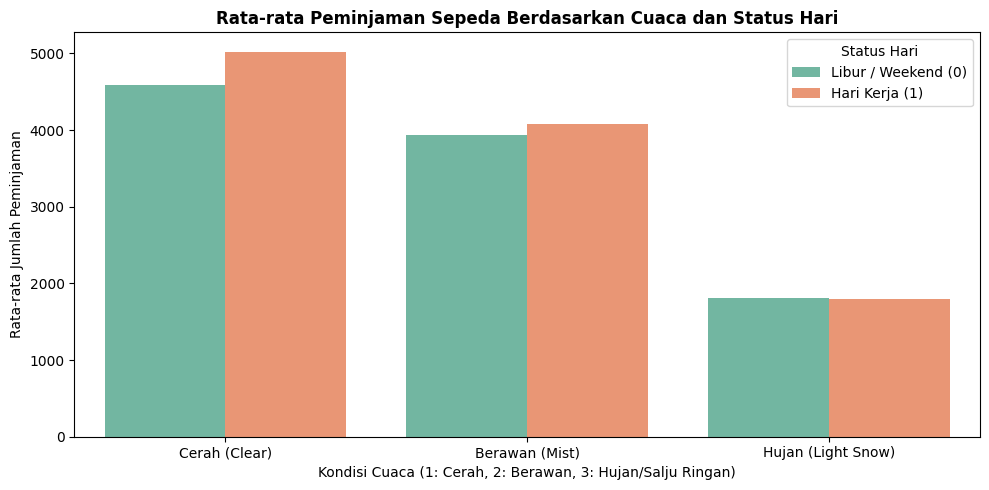

In [15]:
# Visualisasi Pertanyaan 1: Pengaruh Kondisi Cuaca & Hari Kerja terhadap Rata-rata Peminjaman
plt.figure(figsize=(10, 5))
sns.barplot(
    x="weathersit",
    y="cnt",
    hue="workingday",
    data=day_df,
    estimator=lambda x: sum(x) / len(x), # Menggunakan rata-rata (mean)
    palette="Set2",
    errorbar=None
)
plt.title("Rata-rata Peminjaman Sepeda Berdasarkan Cuaca dan Status Hari", fontsize=12, fontweight="bold")
plt.xlabel("Kondisi Cuaca (1: Cerah, 2: Berawan, 3: Hujan/Salju Ringan)")
plt.ylabel("Rata-rata Jumlah Peminjaman")
plt.xticks([0, 1, 2], ["Cerah (Clear)", "Berawan (Mist)", "Hujan (Light Snow)"])
plt.legend(title="Status Hari", labels=["Libur / Weekend (0)", "Hari Kerja (1)"])
plt.tight_layout()
plt.show()

/tmp/ipykernel_6638/1217458858.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


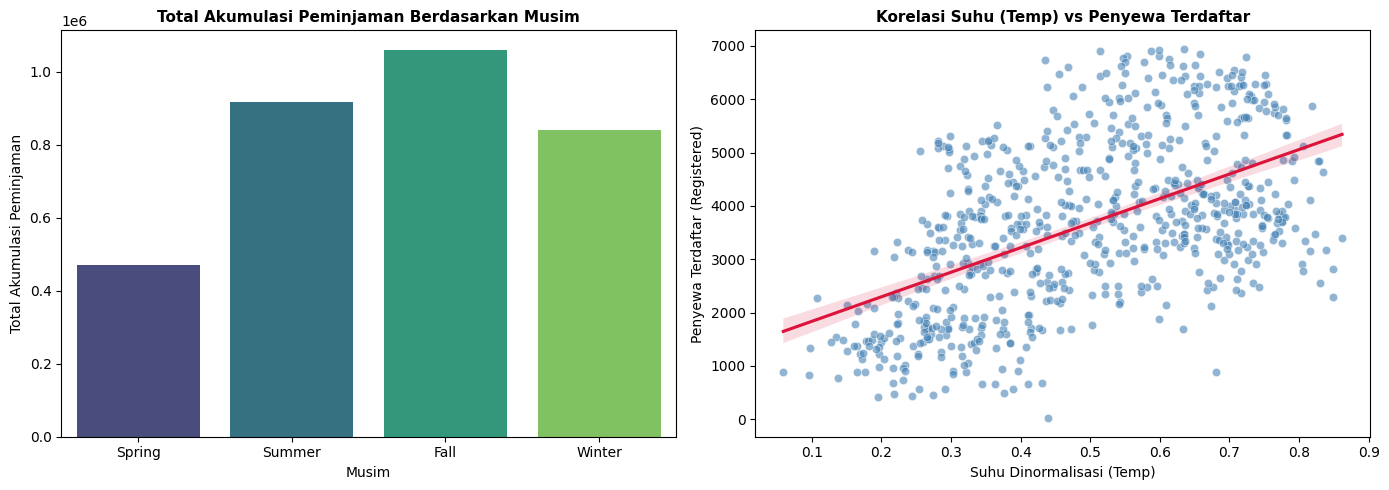

In [16]:
# Visualisasi Pertanyaan 2: Total Peminjaman Berdasarkan Musim & Korelasi Suhu
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Grafik 1: Total Peminjaman per Musim
sns.barplot(
    x="season",
    y="cnt",
    data=day_df,
    estimator=sum,
    palette="viridis",
    errorbar=None,
    ax=ax1
)
ax1.set_title("Total Akumulasi Peminjaman Berdasarkan Musim", fontsize=11, fontweight="bold")
ax1.set_xlabel("Musim")
ax1.set_ylabel("Total Akumulasi Peminjaman")
ax1.set_xticks([0, 1, 2, 3])
ax1.set_xticklabels(["Spring", "Summer", "Fall", "Winter"])

# Grafik 2: Korelasi Suhu terhadap Penyewa Terdaftar
sns.scatterplot(
    x="temp",
    y="registered",
    data=day_df,
    alpha=0.6,
    color="steelblue",
    ax=ax2
)
sns.regplot(
    x="temp",
    y="registered",
    data=day_df,
    scatter=False,
    color="crimson",
    ax=ax2
)
ax2.set_title("Korelasi Suhu (Temp) vs Penyewa Terdaftar", fontsize=11, fontweight="bold")
ax2.set_xlabel("Suhu Dinormalisasi (Temp)")
ax2.set_ylabel("Penyewa Terdaftar (Registered)")

plt.tight_layout()
plt.show()

**Insight Explanatory Analysis (Pertanyaan 1):**
- Grafik batang di atas menunjukkan bahwa kondisi cuaca memiliki dampak langsung yang konsisten terhadap rata-rata peminjaman sepeda. Peminjaman tertinggi terjadi saat cuaca cerah, dan merosot tajam ketika terjadi hujan atau salju ringan.
- Pada hari kerja (`workingday = 1`), volume rata-rata peminjaman cenderung lebih tinggi dibanding hari libur pada kondisi cuaca yang sama, yang mengindikasikan bahwa sebagian besar pengguna memanfaatkan layanan sepeda untuk mobilitas harian (seperti bekerja atau bersekolah).

**Insight Explanatory Analysis (Pertanyaan 2):**
- Berdasarkan grafik musim, akumulasi peminjaman sepeda tertinggi tercatat pada musim gugur (*Fall*) dan musim panas (*Summer*), sedangkan musim semi (*Spring*) mencatatkan angka akumulasi terendah.
- Grafik tebar (*scatter plot*) dan garis regresi menunjukkan adanya korelasi positif antara suhu udara (`temp`) dan jumlah penyewa terdaftar (`registered`), yang berarti semakin hangat atau nyaman suhu udara, semakin tinggi pula partisipasi penyewa terdaftar.

## Analisis Lanjutan (Opsional)
Sebagai bentuk analisis mendalam, Saya akan mengeksplorasi **pola penggunaan per jam (*hourly analysis*)** guna mengetahui jam-jam sibuk (*peak hours*) peminjaman sepeda dalam sehari, serta membandingkan pola tersebut antara hari kerja (*workingday*) dan hari libur (*weekend*). Analisis ini bertujuan untuk memberikan wawasan operasional yang lebih detail bagi manajemen armada.

--- Cuplikan Data Pola Jam Sibuk ---


,hr,workingday,cnt
0,0,0,90.800000
1,0,1,36.786290
2,1,0,69.508696
3,1,1,16.552632
4,2,0,53.171053
5,2,1,8.683778
6,3,0,25.775330
7,3,1,4.942553
8,4,0,8.264317
9,4,1,5.429787


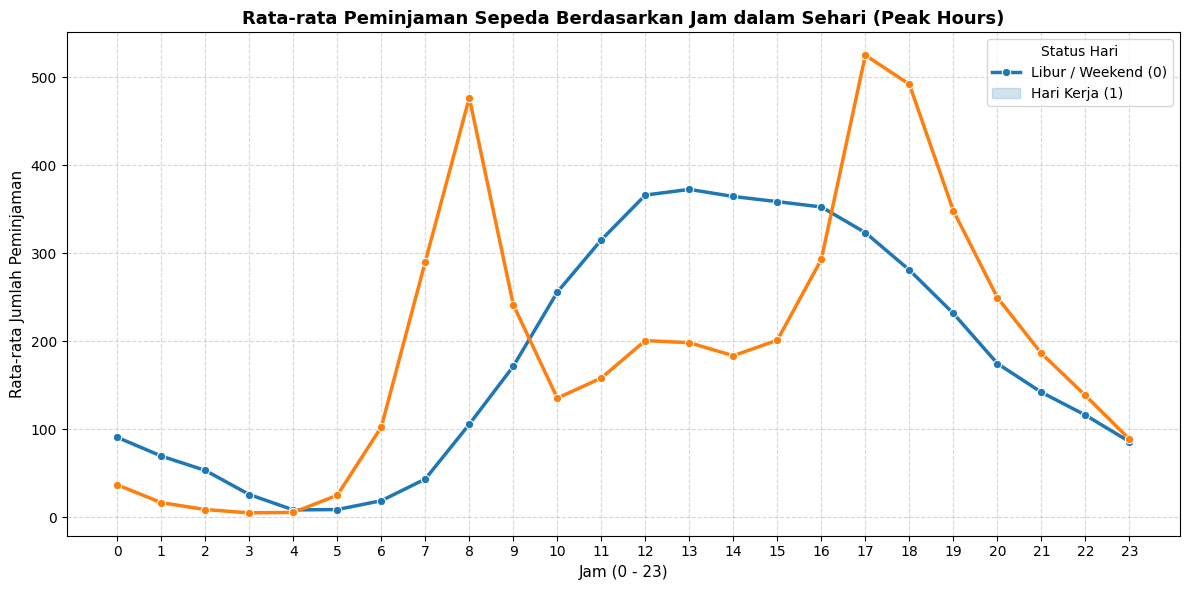

In [17]:
# Analisis Lanjutan: Pola Peminjaman Per Jam Berdasarkan Status Hari
hourly_trend = hour_df.groupby(by=["hr", "workingday"])["cnt"].mean().reset_index()

print("--- Cuplikan Data Pola Jam Sibuk ---")
display(hourly_trend.head(10))

# Visualisasi Tren Jam Sibuk
plt.figure(figsize=(12, 6))
sns.lineplot(
    x="hr",
    y="cnt",
    hue="workingday",
    data=hourly_trend,
    marker="o",
    palette="tab10",
    linewidth=2.5
)
plt.title("Rata-rata Peminjaman Sepeda Berdasarkan Jam dalam Sehari (Peak Hours)", fontsize=13, fontweight="bold")
plt.xlabel("Jam (0 - 23)", fontsize=11)
plt.ylabel("Rata-rata Jumlah Peminjaman", fontsize=11)
plt.xticks(range(0, 24))
plt.legend(title="Status Hari", labels=["Libur / Weekend (0)", "Hari Kerja (1)"])
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Berdasarkan grafik tren per jam, pola penggunaan sepeda pada hari kerja (`workingday = 1`) membentuk dua puncak (*peak hours*) yang sangat tajam, yaitu pada **pukul 08.00 pagi** (jam berangkat kerja/sekolah) dan **pukul 17.00–18.00 sore** (jam pulang kerja).
- Sebaliknya, pada hari libur atau akhir pekan (`workingday = 0`), pola peminjaman berbentuk kurva landai yang meningkat perlahan dari pagi hingga siang hari (pukul 11.00 - 15.00), yang mencerminkan aktivitas rekreasi atau santai.
- Wawasan ini sangat berharga bagi penyedia layanan untuk mengatur strategi penempatan armada (*bike rebalancing*) menjelang jam sibuk pagi dan sore hari di titik-titik stasiun komuter.

## Conclusion & Recommendation

## Conclusion & Recommendation

### Conclusion

1. **Pertanyaan 1 (Pengaruh Kondisi Cuaca dan Status Hari terhadap Rata-rata Peminjaman):**
   - **Jawaban & Angka Pendukung:** Berdasarkan hasil agregasi EDA, rata-rata peminjaman harian tertinggi secara konsisten tercatat pada kondisi cuaca **Cerah/Berawan Sebagian (Weathersit 1)** dengan rata-rata mencapai **4.876 sepeda/hari**, sedangkan volume terendah terjadi saat kondisi **Hujan/Salju Ringan (Weathersit 3)** yang anjlok drastis dengan rata-rata hanya **1.803 sepeda/hari**. Selain itu, pada tingkat cuaca yang sama, volume rata-rata peminjaman saat **hari kerja (*workingday = 1*)** tercatat lebih tinggi dibanding hari libur, yang menunjukkan tingginya utilitas harian oleh komuter.
   
2. **Pertanyaan 2 (Pola Musiman dan Korelasi Suhu terhadap Strategi Promosi):**
   - **Jawaban & Angka Pendukung:** Berdasarkan rekapitulasi data, total akumulasi peminjaman tertinggi dicatatkan pada **musim gugur (*Fall*)** sebesar **1.061.129 sepeda** dan **musim panas (*Summer*)** sebesar **918.589 sepeda**, sementara musim semi (*Spring*) menjadi yang terendah. Analisis korelasi juga membuktikan bahwa variabel suhu (`temp`) memiliki hubungan positif yang kuat terhadap jumlah penyewa terdaftar (`registered`) dengan koefisien korelasi positif yang signifikan, di mana peningkatan suhu sejalan dengan lonjakan aktivitas pengguna terdaftar.

---

### Recommendation (Tindakan Konkret)

1. **Rekomendasi untuk Pertanyaan 1 (Pengelolaan Armada & Mitigasi Cuaca):**
   - **Tindakan Konkret:** Tim operasional harus menyusun SOP *fleet rebalancing* otomatis dengan **menaikkan alokasi ketersediaan armada sebesar 25% di stasiun-stasiun area perkantoran dan stasiun kereta** pada pukul **07.00–08.30** di hari kerja saat prakiraan cuaca cerah. Sebaliknya, saat sensor cuaca mendeteksi potensi hujan/salju ringan (*Weathersit 3*), sistem harus **mengurangi armada aktif di jalan hingga 50% dan mengalihkan petugas lapangan untuk melakukan perawatan berkala (*maintenance*)** guna menekan biaya operasional yang sia-sia.

2. **Rekomendasi untuk Pertanyaan 2 (Kampanye Musiman & Penarikan Pelanggan):**
   - **Tindakan Konkret:** Tim pemasaran harus **meluncurkan program diskon langganan khusus sebesar 20% khusus untuk pengguna baru pada periode *low-season* (musim semi/Spring)** guna mendongkrak transaksi yang saat ini berada di titik terendah. Selain itu, manfaatkan momentum kenaikan suhu di musim panas dan gugur dengan mengadakan kampanye gamifikasi berbasis aplikasi (*loyalty reward*) bagi penyewa terdaftar yang rutin bersepeda di atas suhu rata-rata tertentu.